<a href="https://colab.research.google.com/github/Anjali-4191/PROJECT_MODEL/blob/main/AI_Based_Cardiovascular_Disease_Prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# 1. IMPORT REQUIRED LIBRARIES
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# Suppress unnecessary warnings
warnings.filterwarnings('ignore')
# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:

# ==========================================
# 2. LOAD THE CARDIOVASCULAR DATASET
# ==========================================

import pandas as pd
import os

# Dataset path
file_path = "/content/cardio_train (1).csv"

# Check whether the dataset exists
if os.path.exists(file_path):

    # Load CSV file (dataset uses semicolon separator)
    df = pd.read_csv(file_path, sep=';')

    print("Dataset loaded successfully!")
    print("Shape of dataset:", df.shape)

else:
    raise FileNotFoundError("Dataset file not found. Please check the file path.")

# Display first 5 rows
df.head()


Dataset loaded successfully!
Shape of dataset: (49961, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0.0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1.0
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1.0
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1.0
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0.0


In [8]:
# ============================================
# 3. INITIAL DATASET EXPLORATION
# ============================================

# Display first five records
print("First Five Records:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())
# Display dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe().T)


First Five Records:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0.0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1.0
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1.0
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1.0
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0.0



Dataset Shape:
Number of Rows: 49961
Number of Columns: 13

Column Names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49961 entries, 0 to 49960
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           49961 non-null  int64  
 1   age          49961 non-null  int64  
 2   gender       49961 non-null  int64  
 3   height       49961 non-null  int64  
 4   weight       49961 non-null  float64
 5   ap_hi        49961 non-null  int64  
 6   ap_lo        49961 non-null  int64  
 7   cholesterol  49961 non-null  int64  
 8   gluc         49961 non-null  int64  
 9   smoke        49961 non-null  int64  
 10  alco         49961 non-null  int64  
 11  active       49961 non-null  int64  
 12  cardio       49960 non-null  float64
dtypes: float64(2), int64(11)
memory usage

,count,mean,std,min,25%,50%,75%,max
id,49961.0,35676.161566,20609.537461,0.0,17836.0,35682.0,53508.0,71310.0
age,49961.0,19464.684094,2469.041025,10798.0,17662.0,19703.0,21321.0,23690.0
gender,49961.0,1.346971,0.476011,1.0,1.0,1.0,2.0,2.0
height,49961.0,164.366166,8.190134,55.0,159.0,165.0,170.0,250.0
weight,49961.0,74.230610,14.327859,11.0,65.0,72.0,82.0,200.0
ap_hi,49961.0,128.747183,154.515534,-150.0,120.0,120.0,140.0,16020.0
ap_lo,49961.0,96.972118,200.225599,0.0,80.0,80.0,90.0,11000.0
cholesterol,49961.0,1.363504,0.677197,1.0,1.0,1.0,1.0,3.0
gluc,49961.0,1.225856,0.572023,1.0,1.0,1.0,1.0,3.0
smoke,49961.0,0.088209,0.283601,0.0,0.0,0.0,0.0,1.0


In [9]:
# ============================================
# 4. CHECK DATA QUALITY
# ============================================

# Check missing values
print("Missing Values in Each Column:")
display(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check duplicate records
print("\nTotal Duplicate Records:", df.duplicated().sum())

# Check target variable distribution
# Check target variable distribution
print("\nCardiovascular Disease Distribution:")
display(df['cardio'].value_counts())

Missing Values in Each Column:


,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0



Total Missing Values: 1

Total Duplicate Records: 0

Cardiovascular Disease Distribution:


,count
cardio,
0.0,25028
1.0,24932


([<matplotlib.axis.XTick at 0x7d950596a900>,
 [Text(0, 0, 'No Disease'), Text(1, 0, 'Disease')])

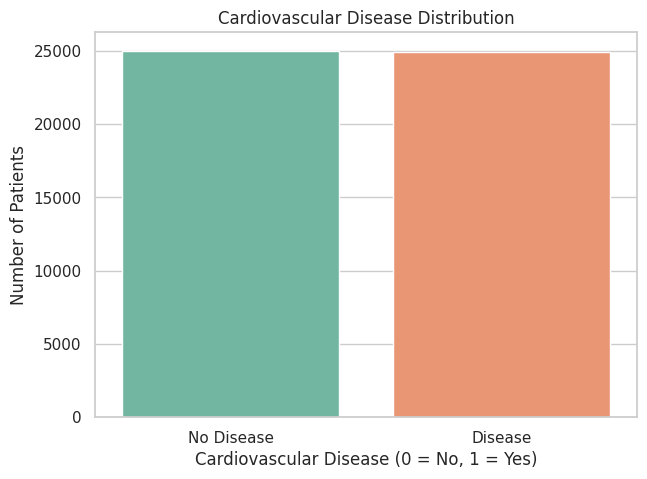

In [10]:
# ============================================
# 1. TARGET VARIABLE DISTRIBUTION
# ============================================

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='cardio', hue='cardio',
              palette='Set2', legend=False)

plt.title('Cardiovascular Disease Distribution')
plt.xlabel('Cardiovascular Disease (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.xticks([0, 1], ['No Disease', 'Disease'])


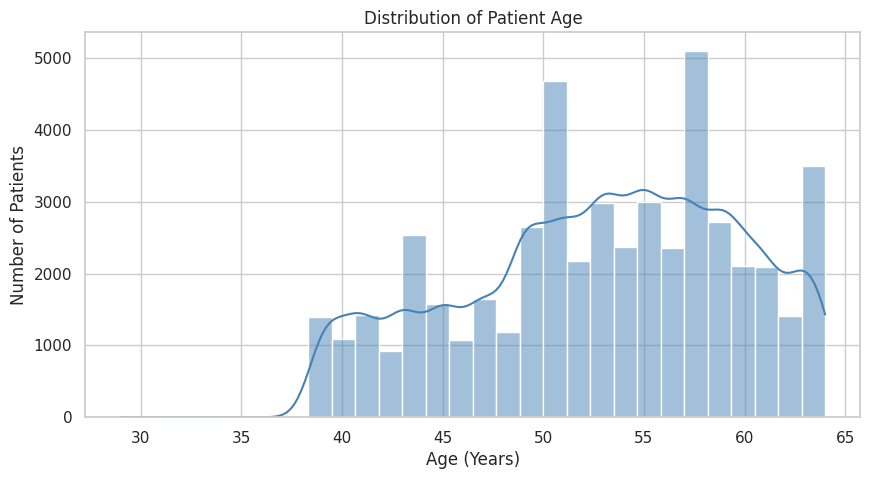

Average Patient Age: 52.79
Minimum Age: 29
Maximum Age: 64


In [11]:
# ============================================
# 2. AGE DISTRIBUTION ANALYSIS
# ============================================

# Convert age from days into years
df['age_years'] = (df['age'] / 365.25).astype(int)

plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='age_years',
             bins=30, kde=True, color='steelblue')

plt.title('Distribution of Patient Age')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Patients')

plt.show()

# Average age of patients
print("Average Patient Age:", round(df['age_years'].mean(), 2))

# Minimum and maximum age
print("Minimum Age:", df['age_years'].min())
print("Maximum Age:", df['age_years'].max())

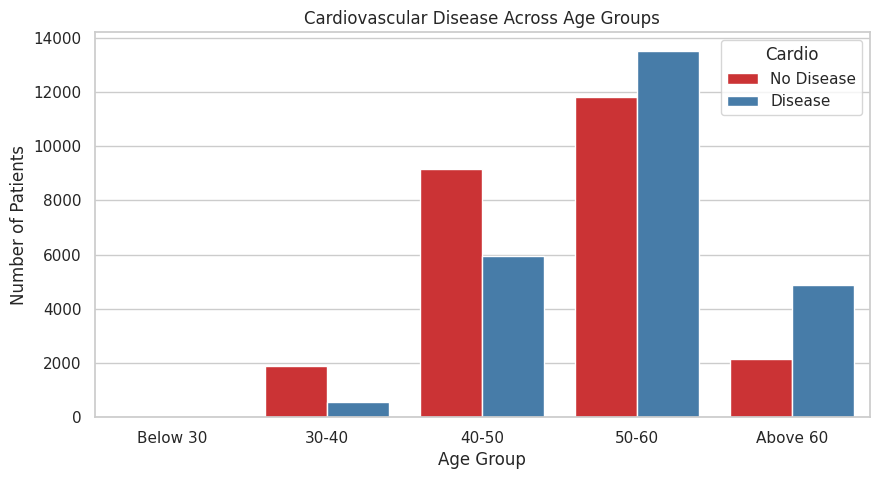

In [12]:
# ============================================
# 3. AGE GROUP ANALYSIS
# ============================================

# Create age groups
df['age_group'] = pd.cut(
    df['age_years'],
    bins=[0, 30, 40, 50, 60, 100],
    labels=['Below 30', '30-40', '40-50', '50-60', 'Above 60']
)

plt.figure(figsize=(10, 5))

sns.countplot(
     data=df,
    x='age_group',
    hue='cardio',
    palette='Set1'
)

plt.title('Cardiovascular Disease Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Number of Patients')
plt.legend(title='Cardio', labels=['No Disease', 'Disease'])

plt.show()


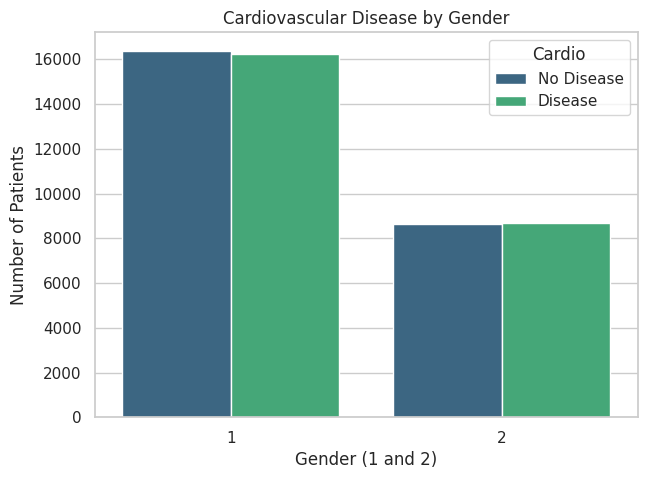

Disease Percentage by Gender:


cardio,0.0,1.0
gender,,
1,50.234483,49.765517
2,49.835593,50.164407


In [13]:
# ============================================
# 4. GENDER-BASED ANALYSIS
# ============================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='cardio',
    palette='viridis'
)
plt.title('Cardiovascular Disease by Gender')
plt.xlabel('Gender (1 and 2)')
plt.ylabel('Number of Patients')
plt.legend(title='Cardio', labels=['No Disease', 'Disease'])

plt.show()

# Calculate disease percentage by gender
gender_analysis = pd.crosstab(
    df['gender'],
    df['cardio'],
    normalize='index'
) * 100
print("Disease Percentage by Gender:")
display(gender_analysis)


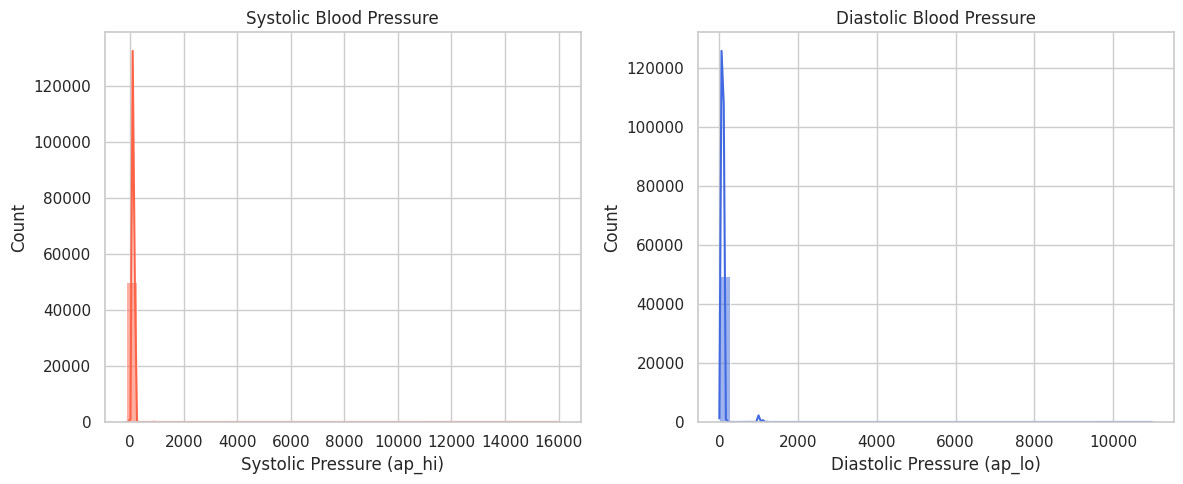

In [14]:
# ============================================
# 5. BLOOD PRESSURE ANALYSIS
# ============================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.histplot(data=df, x='ap_hi',
             bins=40, kde=True, color='tomato')

plt.title('Systolic Blood Pressure')
plt.xlabel('Systolic Pressure (ap_hi)')
plt.subplot(1, 2, 2)

sns.histplot(data=df, x='ap_lo',
             bins=40, kde=True, color='royalblue')

plt.title('Diastolic Blood Pressure')
plt.xlabel('Diastolic Pressure (ap_lo)')

plt.tight_layout()
plt.show()


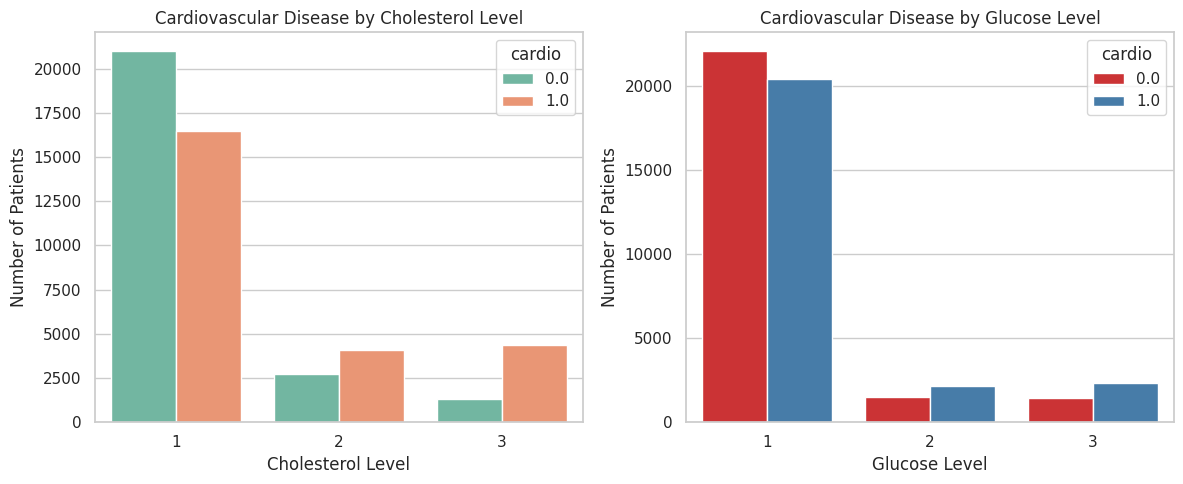

In [15]:
# ============================================
# 6. CHOLESTEROL AND GLUCOSE ANALYSIS
# ============================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.countplot(
    data=df,
    x='cholesterol',
    hue='cardio',
    palette='Set2'
)

plt.title('Cardiovascular Disease by Cholesterol Level')
plt.xlabel('Cholesterol Level')
plt.ylabel('Number of Patients')

plt.subplot(1, 2, 2)

sns.countplot(
    data=df,
    x='gluc',
    hue='cardio',
    palette='Set1'
    )

plt.title('Cardiovascular Disease by Glucose Level')
plt.xlabel('Glucose Level')
plt.ylabel('Number of Patients')

plt.tight_layout()
plt.show()

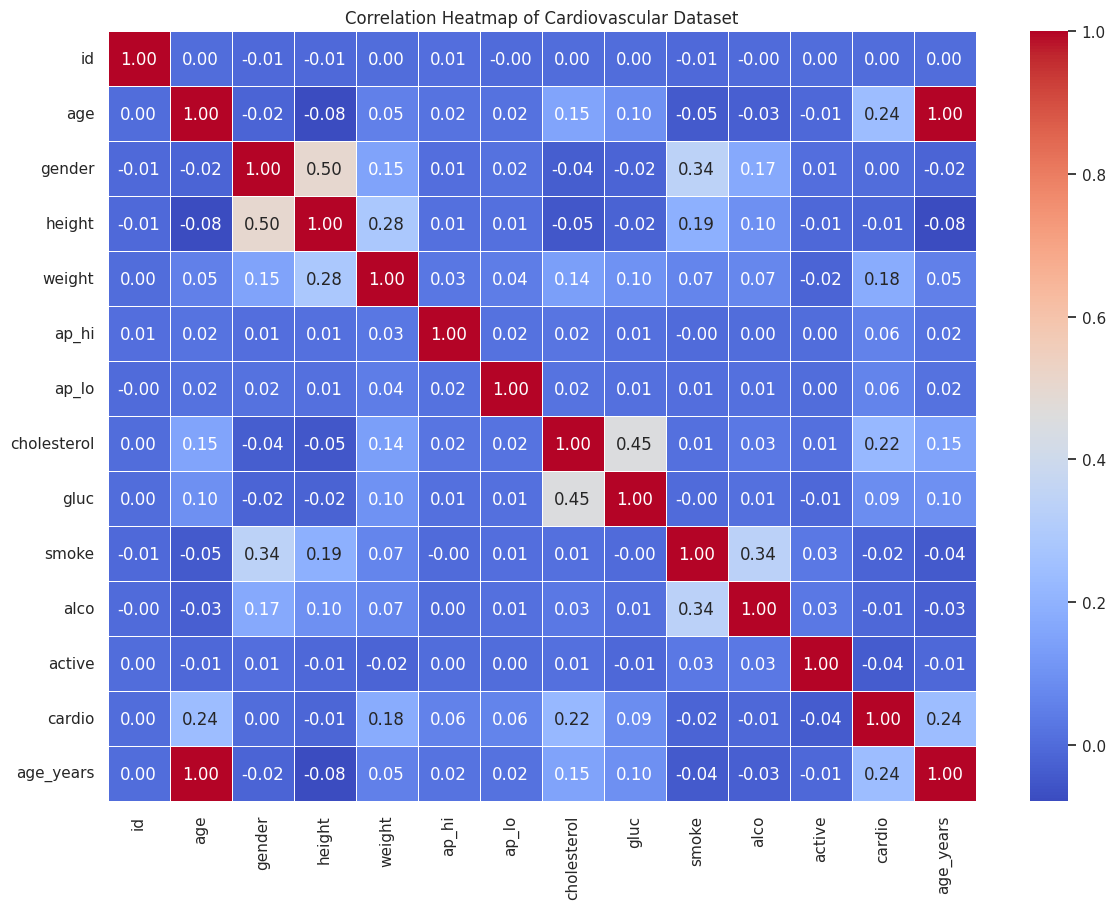

In [16]:
# ============================================
# 7. CORRELATION ANALYSIS
# ============================================

# Select numerical columns
correlation_data = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Cardiovascular Dataset')
plt.show()

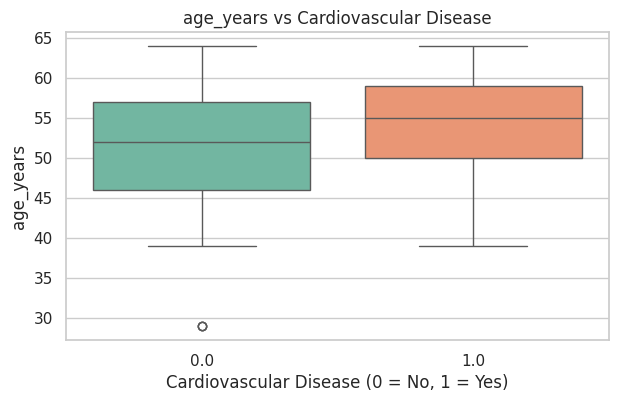

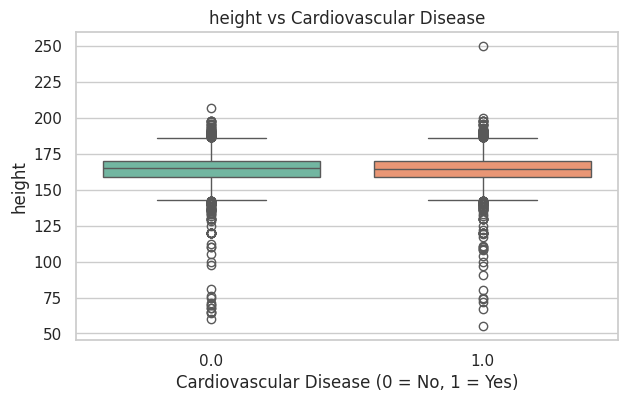

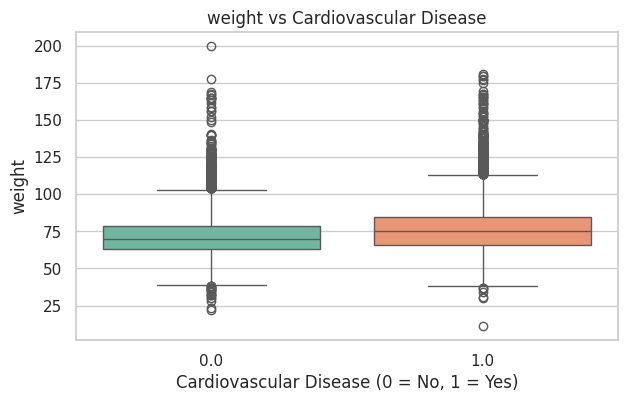

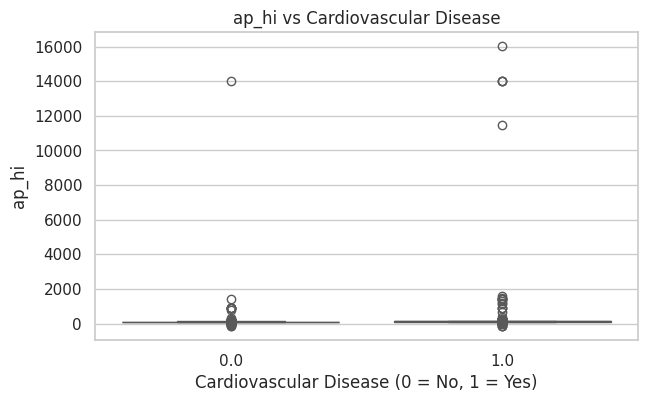

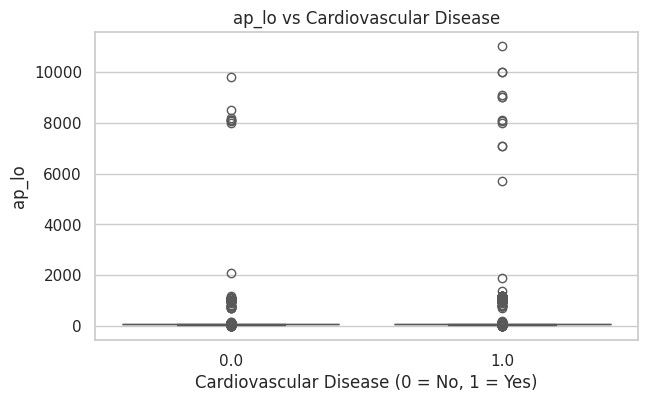

In [17]:
# ============================================
# 8. FEATURE COMPARISON
# ============================================

features = ['age_years', 'height', 'weight',
            'ap_hi', 'ap_lo']

for feature in features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x='cardio',
        y=feature,
        hue='cardio',
        palette='Set2',
        legend=False
    )

    plt.title(f'{feature} vs Cardiovascular Disease')
    plt.xlabel('Cardiovascular Disease (0 = No, 1 = Yes)')
    plt.ylabel(feature)

    plt.show()

In [19]:
# ============================================
# 1. CREATE WORKING COPY
# ============================================

data = df.copy()

print("Original Dataset Shape:", data.shape)

print("\nWorking copy created successfully!")


Original Dataset Shape: (49961, 15)

Working copy created successfully!


In [20]:
# ============================================
# 2. REMOVE DUPLICATE RECORDS
# ============================================

# Count duplicate records
duplicate_count = data.duplicated().sum()

print("Duplicate Records Found:", duplicate_count)

# Remove duplicates
data = data.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", data.shape)

Duplicate Records Found: 0
Dataset Shape After Removing Duplicates: (49961, 15)


In [21]:
# ============================================
# 3. REMOVE UNNECESSARY COLUMNS
# ============================================

# Remove patient ID and original age
data = data.drop(columns=['id', 'age'], errors='ignore')

print("Unnecessary columns removed successfully!")

print("\nRemaining Columns:")
print(data.columns.tolist())

Unnecessary columns removed successfully!

Remaining Columns:
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio', 'age_years', 'age_group']


In [22]:
# ============================================
# 4. HANDLE MISSING VALUES
# ============================================

# Check missing values
print("Missing Values Before Cleaning:")
print(data.isnull().sum())

# Fill missing numerical values using median
for column in data.select_dtypes(include=np.number).columns:

    if data[column].isnull().sum() > 0:

        data[column] = data[column].fillna(data[column].median())
        print("\nMissing Values After Cleaning:")
print(data.isnull().sum().sum())

Missing Values Before Cleaning:
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         1
age_years      0
age_group      0
dtype: int64

Missing Values After Cleaning:
0


In [23]:
# ============================================
# 5. REMOVE INVALID CLINICAL MEASUREMENTS
# ============================================

print("Dataset Shape Before Validation:", data.shape)

# Keep realistic age values
data = data[
    (data['age_years'] >= 18) &
    (data['age_years'] <= 100)
]
# Keep realistic height values (cm)
data = data[
    (data['height'] >= 100) &
    (data['height'] <= 250)
]

# Keep realistic weight values (kg)
data = data[
    (data['weight'] >= 20) &
    (data['weight'] <= 300)
]

# Keep plausible systolic and diastolic blood pressure
data = data[
    (data['ap_hi'] >= 60) &
    (data['ap_hi'] <= 250) &
    (data['ap_lo'] >= 30) &
    (data['ap_lo'] <= 150)
]

# Systolic pressure should be greater than diastolic pressure
data = data[data['ap_hi'] > data['ap_lo']]

print("Dataset Shape After Validation:", data.shape)

print("Invalid clinical measurements removed.")

Dataset Shape Before Validation: (49961, 13)
Dataset Shape After Validation: (48988, 13)
Invalid clinical measurements removed.


In [25]:
# ============================================
# 6. VALIDATE CATEGORICAL FEATURES
# ============================================

categorical_columns = [
    'gender',
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active',
    'cardio'
]

for column in categorical_columns:
    print("\nColumn:", column)
    print("Unique Values:", sorted(data[column].dropna().unique()))

# Check expected category ranges
valid_categories = {
    'gender': [1, 2],
    'cholesterol': [1, 2, 3],
    'gluc': [1, 2, 3],
    'smoke': [0, 1],
    'alco': [0, 1],
    'active': [0, 1],
    'cardio': [0, 1]
}

for column, valid_values in valid_categories.items():

    invalid_count = (~data[column].isin(valid_values)).sum()

    print(f"{column}: {invalid_count} invalid records")


Column: gender
Unique Values: [np.int64(1), np.int64(2)]

Column: cholesterol
Unique Values: [np.int64(1), np.int64(2), np.int64(3)]

Column: gluc
Unique Values: [np.int64(1), np.int64(2), np.int64(3)]

Column: smoke
Unique Values: [np.int64(0), np.int64(1)]

Column: alco
Unique Values: [np.int64(0), np.int64(1)]

Column: active
Unique Values: [np.int64(0), np.int64(1)]

Column: cardio
Unique Values: [np.float64(0.0), np.float64(1.0)]
gender: 0 invalid records
cholesterol: 0 invalid records
gluc: 0 invalid records
smoke: 0 invalid records
alco: 0 invalid records
active: 0 invalid records
cardio: 0 invalid records


In [26]:
# ============================================
# 8. SEPARATE FEATURES AND TARGET
# ============================================

# Independent variables
X = data.drop(columns=['cardio'])

# Dependent variable
y = data['cardio']

print("Independent Variables Shape:", X.shape)

print("Target Variable Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Independent Variables Shape: (48988, 12)
Target Variable Shape: (48988,)

Feature Columns:
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'age_group']

Target Distribution:
cardio
0.0    24779
1.0    24209
Name: count, dtype: int64


In [27]:
# ============================================
# 9. FINAL DATASET VERIFICATION
# ============================================

print("========== FINAL DATASET REPORT ==========")

print("\nDataset Shape:", data.shape)

print("\nMissing Values:", data.isnull().sum().sum())

print("\nDuplicate Records:", data.duplicated().sum())

print("\nFeature Count:", X.shape[1])
print("\nTarget Classes:")
print(y.value_counts())

print("\nData Types:")
print(data.dtypes)

print("\nFirst Five Cleaned Records:")
display(data.head())

print("\nData preprocessing completed successfully!")

========== FINAL DATASET REPORT ==========

Dataset Shape: (48988, 13)

Missing Values: 0

Duplicate Records: 1778

Feature Count: 12

Target Classes:
cardio
0.0    24779
1.0    24209
Name: count, dtype: int64

Data Types:
gender            int64
height            int64
weight          float64
ap_hi             int64
ap_lo             int64
cholesterol       int64
gluc              int64
smoke             int64
alco              int64
active            int64
cardio          float64
age_years         int64
age_group      category
dtype: object

First Five Cleaned Records:


,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,age_group
0,2,168,62.0,110,80,1,1,0,0,1,0.0,50,40-50
1,1,156,85.0,140,90,3,1,0,0,1,1.0,55,50-60
2,1,165,64.0,130,70,3,1,0,0,0,1.0,51,50-60
3,2,169,82.0,150,100,1,1,0,0,1,1.0,48,40-50
4,1,156,56.0,100,60,1,1,0,0,0,0.0,47,40-50



Data preprocessing completed successfully!


In [28]:
# ============================================
# 1. IDENTIFY FEATURE TYPES
# ============================================

# Categorical features
categorical_features = [
    'gender',
    'cholesterol',
    'gluc',
    'smoke',
    'alco',
    'active'
]

# Numerical features
numerical_features = [
    'age_years',
    'height',
    'weight',
    'ap_hi',
    'ap_lo'
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nTotal Features:", len(categorical_features) + len(numerical_features))


Categorical Features:
['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Numerical Features:
['age_years', 'height', 'weight', 'ap_hi', 'ap_lo']

Total Features: 11


In [29]:
# ============================================
# 2. TRAIN-TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Data Shape: (39190, 12)
Testing Data Shape: (9798, 12)

Training Target Distribution:
cardio
0.0    50.581781
1.0    49.418219
Name: proportion, dtype: float64

Testing Target Distribution:
cardio
0.0    50.581751
1.0    49.418249
Name: proportion, dtype: float64


In [30]:
# ============================================
# 3. CREATE PREPROCESSING PIPELINE
# ============================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    drop='first'
    )

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [31]:
# ============================================
# 4. APPLY FEATURE SCALING AND ENCODING
# ============================================

# Learn preprocessing parameters from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data Processed Successfully!")
print("Testing Data Processed Successfully!")
print("\nProcessed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Training Data Processed Successfully!
Testing Data Processed Successfully!

Processed Training Shape: (39190, 13)
Processed Testing Shape: (9798, 13)


In [32]:
# ============================================
# 5. VERIFY FEATURE SCALING
# ============================================

# Extract scaled numerical features
scaled_numerical = X_train_processed[:, :len(numerical_features)]

# Display numerical feature means
print("Scaled Feature Means:")
print(np.round(scaled_numerical.mean(axis=0), 3))

# Display numerical feature standard deviations
print("\nScaled Feature Standard Deviations:")
print(np.round(scaled_numerical.std(axis=0), 3))

Scaled Feature Means:
[-0.  0. -0. -0.  0.]

Scaled Feature Standard Deviations:
[1. 1. 1. 1. 1.]


In [33]:
# ============================================
# 6. DISPLAY PROCESSED DATA
# ============================================

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert processed training data into DataFrame
X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)
# Convert processed testing data into DataFrame
X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Final Processed Training Data:")
display(X_train_df.head())

print("\nFinal Processed Testing Data:")
display(X_test_df.head())

print("\nTotal Processed Features:", len(feature_names))


Final Processed Training Data:


,num__age_years,num__height,num__weight,num__ap_hi,num__ap_lo,cat__gender_2,cat__cholesterol_2,cat__cholesterol_3,cat__gluc_2,cat__gluc_3,cat__smoke_1,cat__alco_1,cat__active_1
23600,-1.447223,-1.311234,0.201196,-1.592617,-2.257948,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2480,0.918849,-0.429480,0.834274,0.196510,0.919657,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
15356,-1.595102,0.830170,-0.150514,-0.399865,-0.139545,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
43566,-0.412066,0.074380,-0.994618,-0.399865,-0.139545,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12514,0.179451,-0.177550,-1.627697,-0.399865,-0.139545,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Final Processed Testing Data:


,num__age_years,num__height,num__weight,num__ap_hi,num__ap_lo,cat__gender_2,cat__cholesterol_2,cat__cholesterol_3,cat__gluc_2,cat__gluc_3,cat__smoke_1,cat__alco_1,cat__active_1
561,-1.299343,-0.555445,0.552906,-0.996241,-1.198746,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
46407,0.770969,0.074380,1.045301,-0.101678,-1.198746,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
48262,1.066728,-1.185269,-0.853934,0.792886,0.919657,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
29107,-0.559946,1.963854,0.271538,-0.399865,-0.139545,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
30441,-0.116307,0.074380,-0.572566,0.196510,-1.198746,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Total Processed Features: 13


In [34]:
# ============================================
# 1. IMPORT DECISION TREE LIBRARIES
# ============================================

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import cross_val_score
print("Decision Tree libraries imported successfully!")

Decision Tree libraries imported successfully!


In [35]:
# ============================================
# 2. CREATE DECISION TREE CLASSIFIER
# ============================================

decision_tree = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])
print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [36]:
# ============================================
# 3. TRAIN DECISION TREE MODEL
# ============================================

decision_tree.fit(X_train, y_train)

print("Decision Tree Model Training Completed!")

Decision Tree Model Training Completed!


In [37]:
# ============================================
# 4. MAKE PREDICTIONS
# ============================================

y_pred_dt = decision_tree.predict(X_test)

print("Predictions Generated Successfully!")

print("\nFirst 20 Actual Values:")
print(y_test.head(20).values)

print("\nFirst 20 Predicted Values:")
print(y_pred_dt[:20])

Predictions Generated Successfully!

First 20 Actual Values:
[0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 1.]

First 20 Predicted Values:
[0. 1. 1. 0. 0. 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 1. 0. 0. 1.]


In [38]:
# ============================================
# 5. MODEL PERFORMANCE EVALUATION
# ============================================

accuracy_dt = accuracy_score(y_test, y_pred_dt)

precision_dt = precision_score(
    y_test, y_pred_dt, zero_division=0
)

recall_dt = recall_score(
    y_test, y_pred_dt, zero_division=0
    )

f1_dt = f1_score(
    y_test, y_pred_dt, zero_division=0
)

print("========== DECISION TREE PERFORMANCE ==========")

print("Accuracy :", round(accuracy_dt * 100, 2), "%")
print("Precision:", round(precision_dt * 100, 2), "%")
print("Recall   :", round(recall_dt * 100, 2), "%")
print("F1-Score :", round(f1_dt * 100, 2), "%")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['No Disease', 'Disease'],
    zero_division=0
))

========== DECISION TREE PERFORMANCE ==========
Accuracy : 72.11 %
Precision: 73.92 %
Recall   : 67.31 %
F1-Score : 70.46 %

Detailed Classification Report:
              precision    recall  f1-score   support

  No Disease       0.71      0.77      0.74      4956
     Disease       0.74      0.67      0.70      4842

    accuracy                           0.72      9798
   macro avg       0.72      0.72      0.72      9798
weighted avg       0.72      0.72      0.72      9798



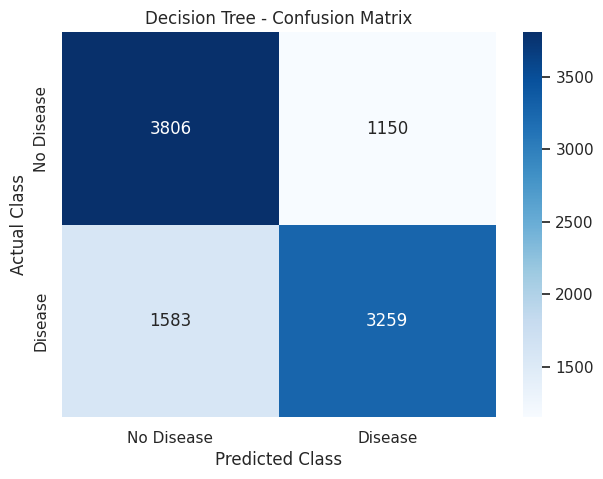

In [39]:
 # ============================================
# 6. CONFUSION MATRIX
# ============================================

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
    )

plt.title('Decision Tree - Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.show()